# 1. Attach the calendar dates and prices

In [6]:
import pandas as pd
import numpy as np

calendar = pd.read_csv("m5-forecasting-accuracy/calendar.csv")
prices = pd.read_csv("m5-forecasting-accuracy/sell_prices.csv")
sales = pd.read_csv("m5-forecasting-accuracy/sales_train_evaluation.csv") 

In [5]:
print("Raw sales shape (Rows, Columns):", sales.shape)

Raw sales shape (Rows, Columns): (30490, 1947)


In [8]:
# 2. Filter to 1 Store (CA_1) and 1 Category (FOODS)
sales_filtered = sales[(sales['store_id'] == 'CA_1') & (sales['cat_id'] == 'FOODS')].copy()

# Keep only the ID columns and the last ~2 years of days (from d_1200 onwards)
id_columns = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
day_columns = [col for col in sales_filtered.columns if col.startswith('d_') and int(col.split('_')[1]) >= 1200]

sales_filtered = sales_filtered[id_columns + day_columns]
print("Filtered sales shape:", sales_filtered.shape)

Filtered sales shape: (1437, 748)


In [9]:
# 3. Flip (Melt) the day columns into rows
# Before: 1 row per item, 742 day columns
# After: 1 row per item per day, with a single 'sales' column
print("Reshaping data from wide to long format...")
df = pd.melt(
    sales_filtered,
    id_vars=id_columns,
    value_vars=day_columns,
    var_name='d',
    value_name='sales'
)

Reshaping data from wide to long format...


In [10]:
# 4. Attach Calendar info (Date, Day of week, Month, Year)
calendar_cols = ['d', 'date', 'wm_yr_wk', 'wday', 'month', 'year', 'event_name_1', 'snap_CA']
df = df.merge(calendar[calendar_cols], on='d', how='left')

In [11]:
# 5. Attach Item Prices
df = df.merge(prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')

In [12]:
# 6. Create a clean day number column (e.g., turning 'd_1200' into the number 1200) for easy sorting
df['day_num'] = df['d'].str.replace('d_', '').astype(int)

In [13]:
# Sort the table by item and day in chronological order
df = df.sort_values(['id', 'day_num']).reset_index(drop=True)

print("Done! Final table shape:", df.shape)
df.head(10)

Done! Final table shape: (1066254, 17)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,wday,month,year,event_name_1,snap_CA,sell_price,day_num
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1200,1,12-05-2014,11415,3,5,2014,NaN,0,2.24,1200
1,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1201,2,13-05-2014,11415,4,5,2014,NaN,0,2.24,1201
2,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1202,0,14-05-2014,11415,5,5,2014,NaN,0,2.24,1202
3,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1203,0,15-05-2014,11415,6,5,2014,NaN,0,2.24,1203
4,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1204,0,16-05-2014,11415,7,5,2014,NaN,0,2.24,1204
5,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1205,2,17-05-2014,11416,1,5,2014,NaN,0,2.24,1205
6,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1206,2,18-05-2014,11416,2,5,2014,NaN,0,2.24,1206
7,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1207,3,19-05-2014,11416,3,5,2014,NaN,0,2.24,1207
8,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1208,1,20-05-2014,11416,4,5,2014,NaN,0,2.24,1208
9,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1209,0,21-05-2014,11416,5,5,2014,NaN,0,2.24,1209


In [32]:
df.tail()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,year,event_name_1,snap_CA,sell_price,day_num,sales_28_days_ago,sales_35_days_ago,avg_sales_7_days,avg_sales_28_days,std_sales_28_days
1066249,FOODS_3_827_CA_1_evaluation,FOODS_3_827,FOODS_3,FOODS,CA_1,CA,d_1937,5,18-05-2016,11616,...,2016,NaN,0,1.0,1937,3.0,3.0,7.714286,5.035714,4.194195
1066250,FOODS_3_827_CA_1_evaluation,FOODS_3_827,FOODS_3,FOODS,CA_1,CA,d_1938,7,19-05-2016,11616,...,2016,NaN,0,1.0,1938,3.0,8.0,7.000000,5.035714,4.194195
1066251,FOODS_3_827_CA_1_evaluation,FOODS_3_827,FOODS_3,FOODS,CA_1,CA,d_1939,2,20-05-2016,11616,...,2016,NaN,0,1.0,1939,5.0,5.0,7.000000,5.071429,4.189304
1066252,FOODS_3_827_CA_1_evaluation,FOODS_3_827,FOODS_3,FOODS,CA_1,CA,d_1940,10,21-05-2016,11617,...,2016,NaN,0,1.0,1940,3.0,5.0,6.714286,4.964286,4.203016
1066253,FOODS_3_827_CA_1_evaluation,FOODS_3_827,FOODS_3,FOODS,CA_1,CA,d_1941,5,22-05-2016,11617,...,2016,NaN,0,1.0,1941,21.0,19.0,7.000000,5.607143,5.159237


# 2. Feature Engineering

In [14]:
print("Creating past sales clues...")

# 1. Clue 1 & 2: Exact sales 4 weeks ago (28 days) and 5 weeks ago (35 days)
df['sales_28_days_ago'] = df.groupby('id')['sales'].shift(28)
df['sales_35_days_ago'] = df.groupby('id')['sales'].shift(35)

Creating past sales clues...


In [15]:
# 2. Clue 3 & 4: Average daily sales over 7-day and 28-day windows
# (We use 'sales_28_days_ago' as our starting point so we never peek into the future)
df['avg_sales_7_days'] = df.groupby('id')['sales_28_days_ago'].transform(lambda x: x.rolling(7).mean())
df['avg_sales_28_days'] = df.groupby('id')['sales_28_days_ago'].transform(lambda x: x.rolling(28).mean())

# Also calculate how much sales fluctuate (Standard Deviation) over 28 days
# This is super helpful for knowing if an item has steady or unpredictable demand!
df['std_sales_28_days'] = df.groupby('id')['sales_28_days_ago'].transform(lambda x: x.rolling(28).std())

In [16]:
# 3. Clean up text columns so the ML model can read them
# Convert text columns (like item_id, dept_id, event_name_1) into 'category' type
categorical_cols = ['item_id', 'dept_id', 'event_name_1']
for col in categorical_cols:
    df[col] = df[col].astype('category')

In [17]:
# 4. Remove the first ~8 weeks of rows where past clues are blank (NaN)
# (Because the very first day in our table doesn't have a "28 days ago" yet!)
df_clean = df.dropna(subset=['avg_sales_28_days', 'sell_price']).reset_index(drop=True)

In [18]:
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))

df_clean[['id', 'date', 'sales', 'sell_price', 'sales_28_days_ago', 'avg_sales_7_days', 'avg_sales_28_days']].head(10)

Rows before cleaning: 1066254
Rows after cleaning: 973729


,id,date,sales,sell_price,sales_28_days_ago,avg_sales_7_days,avg_sales_28_days
0,FOODS_1_001_CA_1_evaluation,06-07-2014,0,2.24,1.0,0.857143,0.892857
1,FOODS_1_001_CA_1_evaluation,07-07-2014,1,2.24,0.0,0.714286,0.857143
2,FOODS_1_001_CA_1_evaluation,08-07-2014,0,2.24,0.0,0.714286,0.785714
3,FOODS_1_001_CA_1_evaluation,09-07-2014,1,2.24,0.0,0.714286,0.785714
4,FOODS_1_001_CA_1_evaluation,10-07-2014,0,2.24,0.0,0.714286,0.785714
5,FOODS_1_001_CA_1_evaluation,11-07-2014,0,2.24,1.0,0.571429,0.821429
6,FOODS_1_001_CA_1_evaluation,12-07-2014,0,2.24,2.0,0.571429,0.821429
7,FOODS_1_001_CA_1_evaluation,13-07-2014,1,2.24,4.0,1.000000,0.892857
8,FOODS_1_001_CA_1_evaluation,14-07-2014,0,2.24,1.0,1.142857,0.821429
9,FOODS_1_001_CA_1_evaluation,15-07-2014,0,2.24,1.0,1.285714,0.821429


# 3. Train the Machine Learning Model (LightGBM)

In [19]:
!pip install lightgbm scikit-learn matplotlib

  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)


In [4]:
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Choose the Clues (Features) and the Target (What we want to predict)
feature_columns = [
    'item_id', 'dept_id', 'wday', 'month', 'year', 
    'event_name_1', 'snap_CA', 'sell_price',
    'sales_28_days_ago', 'sales_35_days_ago', 
    'avg_sales_7_days', 'avg_sales_28_days', 'std_sales_28_days'
]
target_column = 'sales'

In [21]:
# 2. Split strictly by time:
# Train on days before 1914 | Test on the last 28 days (1914 to 1941)
train_data = df_clean[df_clean['day_num'] < 1914].copy()
test_data  = df_clean[df_clean['day_num'] >= 1914].copy()

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_test = test_data[feature_columns]
y_test = test_data[target_column]

print(f"Training rows: {len(X_train)} | Testing rows (Last 28 days): {len(X_test)}")

Training rows: 933493 | Testing rows (Last 28 days): 40236


In [23]:
# 3. Create and Train the LightGBM Model
# Note: objective='tweedie' helps the model handle items that have many 0-sale days!
model = lgb.LGBMRegressor(
    objective='tweedie',
    tweedie_variance_power=1.1,
    n_estimators=500,        # Maximum number of trees
    learning_rate=0.05,      # How fast the model learns
    random_state=42,
    n_jobs=-1                # Uses all CPU cores so it trains fast
)

print("Training the model... (This takes about 10-20 seconds)")
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=50)]
)

Training the model... (This takes about 10-20 seconds)


D:\Anaconda\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.048344 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 933493, number of used features: 13
[LightGBM] [Info] Start training from score 0.730413
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[114]	valid_0's tweedie: 21.9741


,learning_rate,0.05
,n_estimators,500
,objective,'tweedie'
,random_state,42
,n_jobs,-1
,tweedie_variance_power,1.1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None


In [30]:
# 4. Predict Sales for the Last 28 Days
test_data['predicted_sales'] = model.predict(X_test)
# Ensure no negative predictions
test_data['predicted_sales'] = test_data['predicted_sales'].clip(lower=0)

In [25]:
# 5. Check Accuracy (How off is our model on average per item per day?)
rmse = np.sqrt(mean_squared_error(y_test, test_data['predicted_sales']))
mae = mean_absolute_error(y_test, test_data['predicted_sales'])

print("\n--- Model Accuracy on the 28-Day Test Period ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} units")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} units")


--- Model Accuracy on the 28-Day Test Period ---
Mean Absolute Error (MAE): 1.49 units
Root Mean Squared Error (RMSE): 2.75 units


# 4. Visual Graphs

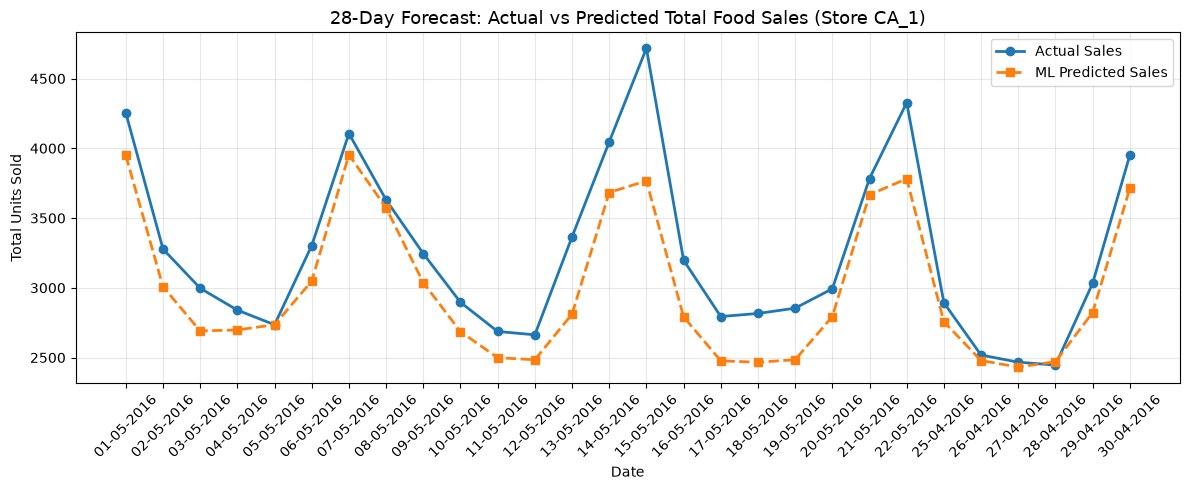

In [26]:
# Plot 1: Actual vs Predicted Total Daily Food Sales across the 28 Test Days
daily_summary = test_data.groupby('date')[['sales', 'predicted_sales']].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily_summary.index, daily_summary['sales'], label='Actual Sales', marker='o', linewidth=2)
plt.plot(daily_summary.index, daily_summary['predicted_sales'], label='ML Predicted Sales', marker='s', linestyle='--', linewidth=2)
plt.title('28-Day Forecast: Actual vs Predicted Total Food Sales (Store CA_1)', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

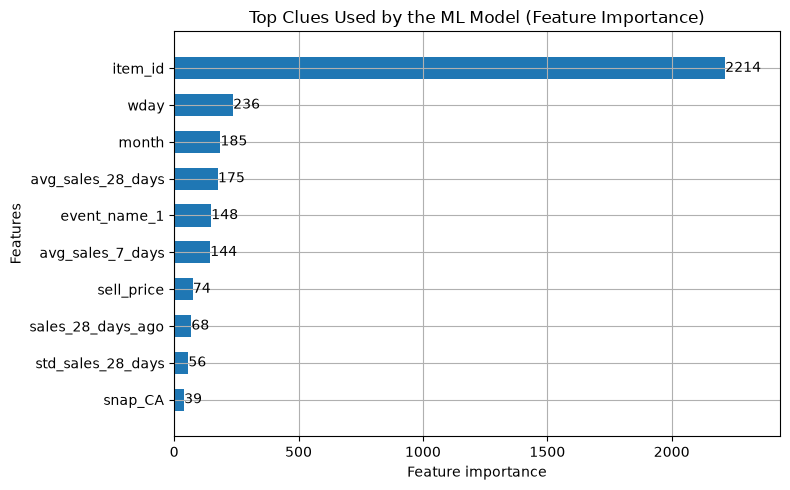

In [27]:
# Plot 2: Which Clues Mattered Most to the Model?
lgb.plot_importance(model, max_num_features=10, height=0.6, figsize=(8, 5), 
                    title="Top Clues Used by the ML Model (Feature Importance)")
plt.tight_layout()
plt.show()

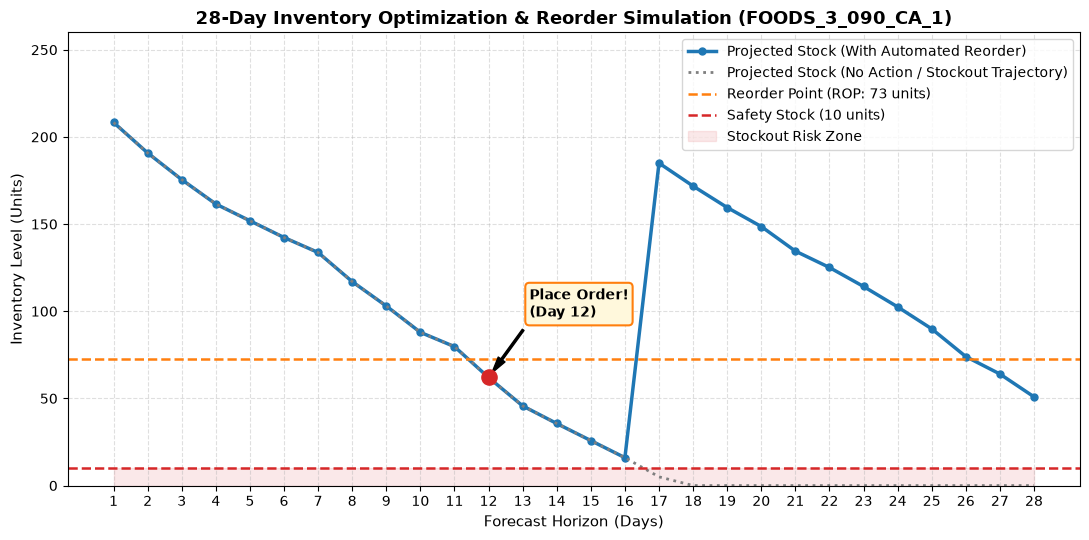

In [5]:
np.random.seed(42)
forecasted_sales = np.random.uniform(8, 18, size=28).round(1) 
days = np.arange(1, 29)

item_name = "FOODS_3_090_CA_1"  # Example M5 Item ID
initial_stock = 220             # Starting inventory on Day 1
lead_time_days = 5              # Days it takes for a restock order to arrive
service_level_z = 1.65          # 95% service level (Z-score)
order_quantity = 180            # Standard restock batch size

# Use your model's features (or calculate from the forecast)
avg_daily_sales = np.mean(forecasted_sales)
std_daily_sales = np.std(forecasted_sales) # Or pull from your 'std_sales_28_days' column

# --- 2. CALCULATE THRESHOLDS ---
safety_stock = service_level_z * std_daily_sales * np.sqrt(lead_time_days)
reorder_point = (avg_daily_sales * lead_time_days) + safety_stock

# --- 3. SIMULATE 28-DAY INVENTORY DEPLETION ---
inventory_no_restock = []
inventory_with_restock = []

curr_stock_no_action = initial_stock
curr_stock_managed = initial_stock
order_triggered_day = None
delivery_day = None

for day, demand in zip(days, forecasted_sales):
    # Receive restock if today is the delivery day
    if day == delivery_day:
        curr_stock_managed += order_quantity
        
    # Deduct daily forecasted demand
    curr_stock_no_action = max(0, curr_stock_no_action - demand)
    curr_stock_managed = max(0, curr_stock_managed - demand)
    
    inventory_no_restock.append(curr_stock_no_action)
    inventory_with_restock.append(curr_stock_managed)
    
    # Trigger order the first time stock dips below the Reorder Point
    if curr_stock_managed <= reorder_point and order_triggered_day is None:
        order_triggered_day = day
        delivery_day = day + lead_time_days

# --- 4. PLOT THE VISUALIZATION ---
plt.figure(figsize=(11, 5.5))

# Plot managed vs. unmanaged inventory curves
plt.plot(days, inventory_with_restock, label='Projected Stock (With Automated Reorder)', 
         color='#1f77b4', linewidth=2.5, marker='o', markersize=5)
plt.plot(days, inventory_no_restock, label='Projected Stock (No Action / Stockout Trajectory)', 
         color='#7f7f7f', linestyle=':', linewidth=2)

# Plot Reorder Point & Safety Stock lines
plt.axhline(reorder_point, color='#ff7f0e', linestyle='--', linewidth=1.8, 
            label=f'Reorder Point (ROP: {reorder_point:.0f} units)')
plt.axhline(safety_stock, color='#d62728', linestyle='--', linewidth=1.8, 
            label=f'Safety Stock ({safety_stock:.0f} units)')

# Highlight the danger zone
plt.fill_between(days, 0, safety_stock, color='#d62728', alpha=0.1, label='Stockout Risk Zone')

# Annotate the exact day the order is placed
if order_triggered_day:
    trig_y = inventory_with_restock[order_triggered_day - 1]
    plt.scatter(order_triggered_day, trig_y, color='#d62728', s=120, zorder=5)
    plt.annotate(f'Place Order!\n(Day {order_triggered_day})',
                 xy=(order_triggered_day, trig_y),
                 xytext=(order_triggered_day + 1.2, trig_y + 35),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                 fontsize=10, fontweight='bold',
                 bbox=dict(boxstyle="round,pad=0.3", fc="#fff8dc", ec="#ff7f0e", lw=1.5))

plt.title(f'28-Day Inventory Optimization & Reorder Simulation ({item_name})', fontsize=13, fontweight='bold')
plt.xlabel('Forecast Horizon (Days)', fontsize=11)
plt.ylabel('Inventory Level (Units)', fontsize=11)
plt.xticks(days)
plt.ylim(0, max(initial_stock, max(inventory_with_restock)) + 40)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# 5. Inventory Optimization and Business Cost Simulation

In [28]:
# 1. Define Business Rules
lead_time_days = 7
z_score_95 = 1.645  # Standard statistical multiplier for 95% service level
holding_cost_per_unit = 0.50   # Cost of keeping 1 unsold item in the backroom ($0.50)
stockout_cost_per_unit = 2.00  # Profit lost when a customer sees an empty shelf ($2.00)

# 2. Add the Lazy Manager's Baseline (Just use the past 28-day average as the forecast)
# We already calculated 'avg_sales_28_days' in Step 2!
test_data['naive_predicted_sales'] = test_data['avg_sales_28_days']

# 3. Calculate daily errors for both methods
test_data['ml_error'] = test_data['sales'] - test_data['predicted_sales']
test_data['naive_error'] = test_data['sales'] - test_data['naive_predicted_sales']

# 4. Group by Item to calculate the final Inventory Policy
print("Calculating Safety Stock and Reorder Points per item...")
inventory_policy = test_data.groupby('id').agg(
    actual_28d_sales=('sales', 'sum'),
    ml_forecast_28d=('predicted_sales', 'sum'),
    naive_forecast_28d=('naive_predicted_sales', 'sum'),
    ml_daily_avg=('predicted_sales', 'mean'),
    naive_daily_avg=('naive_predicted_sales', 'mean'),
    # RMSE is used as the standard deviation of forecast error
    ml_rmse=('ml_error', lambda x: np.sqrt(np.mean(x**2))),
    naive_rmse=('naive_error', lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

# 5. Calculate Safety Stock (SS) and Reorder Point (ROP) for both methods
# ML Policy
inventory_policy['ml_safety_stock'] = np.ceil(z_score_95 * inventory_policy['ml_rmse'] * np.sqrt(lead_time_days))
inventory_policy['ml_ROP'] = np.ceil((inventory_policy['ml_daily_avg'] * lead_time_days) + inventory_policy['ml_safety_stock'])

# Naive Policy
inventory_policy['naive_safety_stock'] = np.ceil(z_score_95 * inventory_policy['naive_rmse'] * np.sqrt(lead_time_days))
inventory_policy['naive_ROP'] = np.ceil((inventory_policy['naive_daily_avg'] * lead_time_days) + inventory_policy['naive_safety_stock'])

# 6. Simulate the Business Impact: Which method costs the store more money?
# Total stock prepared for the 28 days = Forecasted Sales + Safety Stock
ml_prepared_stock = inventory_policy['ml_forecast_28d'] + inventory_policy['ml_safety_stock']
naive_prepared_stock = inventory_policy['naive_forecast_28d'] + inventory_policy['naive_safety_stock']

# Calculate Lost Sales (Stockouts) and Overstock
inventory_policy['ml_overstock'] = np.maximum(0, ml_prepared_stock - inventory_policy['actual_28d_sales'])
inventory_policy['ml_lost_sales'] = np.maximum(0, inventory_policy['actual_28d_sales'] - ml_prepared_stock)

inventory_policy['naive_overstock'] = np.maximum(0, naive_prepared_stock - inventory_policy['actual_28d_sales'])
inventory_policy['naive_lost_sales'] = np.maximum(0, inventory_policy['actual_28d_sales'] - naive_prepared_stock)

# 7. Calculate Financial Costs
inventory_policy['ml_total_cost'] = (inventory_policy['ml_overstock'] * holding_cost_per_unit) + (inventory_policy['ml_lost_sales'] * stockout_cost_per_unit)
inventory_policy['naive_total_cost'] = (inventory_policy['naive_overstock'] * holding_cost_per_unit) + (inventory_policy['naive_lost_sales'] * stockout_cost_per_unit)

# 8. Print the Final Report!
print("\n--- INVENTORY FINANCIAL SUMMARY (28 Days, Store CA_1) ---")
total_ml_cost = inventory_policy['ml_total_cost'].sum()
total_naive_cost = inventory_policy['naive_total_cost'].sum()
savings = total_naive_cost - total_ml_cost

print(f"Total Cost using Lazy Average Baseline: ${total_naive_cost:,.2f}")
print(f"Total Cost using Machine Learning:      ${total_ml_cost:,.2f}")
print(f"Total Money Saved by your ML Model:     ${savings:,.2f} in just 1 month at 1 store!\n")

print("--- EXECUTABLE INVENTORY POLICY (Top 5 Items) ---")
display_cols = ['id', 'actual_28d_sales', 'ml_forecast_28d', 'ml_safety_stock', 'ml_ROP', 'ml_total_cost']
print(inventory_policy[display_cols].head())

Calculating Safety Stock and Reorder Points per item...

--- INVENTORY FINANCIAL SUMMARY (28 Days, Store CA_1) ---
Total Cost using Lazy Average Baseline: $29,548.55
Total Cost using Machine Learning:      $26,330.44
Total Money Saved by your ML Model:     $3,218.11 in just 1 month at 1 store!

--- EXECUTABLE INVENTORY POLICY (Top 5 Items) ---
                            id  actual_28d_sales  ml_forecast_28d  \
0  FOODS_1_001_CA_1_evaluation                23        29.726061   
1  FOODS_1_002_CA_1_evaluation                20        13.685014   
2  FOODS_1_003_CA_1_evaluation                20        22.978299   
3  FOODS_1_004_CA_1_evaluation                95        14.166481   
4  FOODS_1_005_CA_1_evaluation                42        33.487331   

   ml_safety_stock  ml_ROP  ml_total_cost  
0              7.0    15.0       6.863030  
1              4.0     8.0       4.629971  
2              5.0    11.0       3.989149  
3             16.0    20.0     129.667037  
4             10.0 

In [29]:
print("Saving results for the web dashboard...")

# Save the final inventory policy table
inventory_policy.to_csv('inventory_dashboard_data.csv', index=False)

# Save the daily predictions (so we can plot them over time)
test_data.to_csv('daily_forecasts.csv', index=False)

print("Saved successfully! You are ready to build the dashboard.")

Saving results for the web dashboard...
Saved successfully! You are ready to build the dashboard.
